# 3. Circumpolar intensification and position (Sect. 3.2, Fig. 3, Figs. S3, S4, S6 and S7)

Companion notebook of **Martí-Solana et al., "Observational constraints on eddy saturation in the Antarctic Circumpolar Current"** (State of the Planet, Ocean State Report 11).

This notebook covers the circumpolar results: the trends of KE and EKE averaged over the ACC band and between the fronts, the position of the energetic pathway against that of a fixed ADT contour, the comparison of the all-satellite and two-satellite altimetry products, and the comparison with previous studies.

It runs from the processed outputs in `outputs/` only (no raw data, no download), in about three minutes. Every figure is drawn by its script in `figures/`; the cells before each figure load the tables behind it and print the values quoted in the paper. The scripts that produced each table from the raw data are named in the text and listed in the README.

In [1]:
from pathlib import Path
import io, os, subprocess, sys, tempfile
import numpy as np, pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "src" / "osr11").is_dir() else ROOT.parent      # works from the repository root or from notebooks/
OUT = ROOT / "outputs"                                                 # processed outputs distributed with the repository
FIGDIR = Path(tempfile.mkdtemp(prefix="osr11_nb_"))                    # figures are re-rendered here, not into rendered/
pd.set_option("display.float_format", lambda v: f"{v:.3g}")


def render(script, width=1700):
    """Run one script of figures/ on outputs/ and show the figure it writes (PNG, 600 dpi, reduced here for display)."""
    args = [str(OUT), str(FIGDIR)] if script.startswith("figS") else [str(FIGDIR)]
    r = subprocess.run([sys.executable, str(ROOT / "figures" / script), *args], capture_output=True, text=True,
                       env=dict(os.environ, MPLBACKEND="Agg"))
    assert r.returncode == 0, r.stderr[-3000:]
    png = max((FIGDIR / "png").glob("*.png"), key=lambda p: p.stat().st_mtime)
    from PIL import Image as PILImage
    im = PILImage.open(png).convert("RGB"); im.thumbnail((width, 3 * width)); buf = io.BytesIO(); im.save(buf, "JPEG", quality=88)
    display(Image(data=buf.getvalue(), format="jpeg"))
    print(png.name, "written to", FIGDIR / "png")


def ci(row, s="slope", lo="lo", hi="hi", p="p", unit=""):
    pv = "p ≤ 0.003" if row[p] < 0.0034 else f"p = {row[p]:.2g}"          # 300 surrogates: the smallest attainable p is 1/301
    return f"{row[s]:+.1f} [{row[lo]:+.1f}, {row[hi]:+.1f}] {unit}, {pv}"


## KE and EKE averaged over the ACC band

Monthly band means (`scripts/02_circumpolar/02a_energy.py`) and their trends (`scripts/05_stats/05a_retest.py`, `05b_retest_summary.py`).

In [2]:
RT = pd.read_csv(OUT / "retest" / "retest_summary.csv").set_index("key")
A5 = pd.read_csv(OUT / "a5" / "a5_series_allsat.csv")
for v in ("KE", "EKE"):
    r = RT.loc[f"allsat|ACC_{v}|2001-2025"]
    print(f"{v:3s}: {r.pct_per_decade:+.1f} % per decade ({10 * r.slope:+.1f} cm2 s-2 per decade), " + ("p ≤ 0.003" if r.p_new < 0.0034 else f"p = {r.p_new:.2g}"))
e = A5.ACC_EKE; print(f"EKE, 2018-2025 mean over 2001-2017 mean: {100 * (e[A5.year >= 2018].mean() / e[A5.year <= 2017].mean() - 1):+.0f} %")
c = RT[RT.family == "CONTRAST"]; c = c[c.index.str.contains("allsat") & c.index.str.contains("ACC")]
c[["slope", "ci_lo", "ci_hi", "p_new"]].rename(columns={"slope": "contrast (percentage points per decade)"}).round(2)

KE : +4.9 % per decade (+13.6 cm2 s-2 per decade), p ≤ 0.003
EKE: +8.0 % per decade (+19.8 cm2 s-2 per decade), p = 0.017
EKE, 2018-2025 mean over 2001-2017 mean: +13 %


,contrast (percentage points per decade),ci_lo,ci_hi,p_new
key,,,,
ACC EKE-KE allsat,3,-0.09,6.09,0.06


The table is the EKE − KE contrast: the trend of the difference of the mean-normalised series, in percentage points per decade.

## EKE between the fronts, by longitude

In [3]:
T = pd.read_csv(OUT / "drake" / "dk12" / "dk12_band_trends_allsat.csv")
print(f"2-degree bins: {len(T)}; positive EKE trend: {100 * (T.slope_dec > 0).mean():.0f} %; significant: {int((T.p < 0.05).sum())}")
T.nlargest(8, "slope_dec")[["lon", "slope_dec", "lo", "hi", "p"]].rename(columns={"lon": "bin centre (deg E)", "slope_dec": "trend (cm2 s-2 per decade)"}).round(3)

2-degree bins: 180; positive EKE trend: 91 %; significant: 39


,bin centre (deg E),trend (cm2 s-2 per decade),lo,hi,p
167,155,103,12.8,193,0.026
166,153,103,24.2,181,0.02
73,-33,83.6,31,136,0.02
168,157,81.1,6.82,155,0.033
163,147,80.3,-2.56,163,0.066
164,149,78.2,-14.1,171,0.099
72,-35,69.7,7.48,132,0.04
23,-133,63.2,3.62,123,0.046


## Position: energetic pathway against a fixed ADT contour

Circumpolar means over the 1826 retained tracks (`02p_pathway_products.py`) and the same by 2° longitude bin (`02o_pathway_bins.py`).

In [4]:
X7 = pd.read_csv(OUT / "x7" / "x7_trends.csv"); c = X7[X7.region == "circumpolar"].set_index("series")
print("half-power latitude:", ci(c.loc["lat_hp"], unit="km per decade"))
print("fixed ADT contour  :", ci(c.loc["lat_contour"], unit="km per decade"))
print("ADT at the pathway :", ci(c.loc["adt_hp"], unit="cm per decade"))
imp = pd.read_csv(OUT / "x7" / "x7_implied_shift.csv").set_index("region").loc["circumpolar"]
print(f"implied by the ADT rise: {imp.implied_contour_shift_km_per_decade:+.0f} km per decade (median gradient {imp.median_grad_cm_per_10km:.1f} cm per 10 km)")

B = pd.read_csv(OUT / "x6" / "x6_relthr_bins.csv")
print(f"\nby 2-degree bin ({len(B)} bins): median half-power trend {B.hp_slope.median():+.1f} km per decade; significant in {int((B.hp_p < 0.05).sum())}"
      f" ({int(((B.hp_p < 0.05) & (B.hp_slope > 0)).sum())} northward)")
cb = B.dropna(subset=["contour_slope"])
print(f"fixed contour: median {cb.contour_slope.median():+.0f} km per decade; significant in {int((cb.contour_p < 0.05).sum())} of {len(cb)} bins, "
      f"{int(((cb.contour_p < 0.05) & (cb.contour_slope < 0)).sum())} of them southward")
T2 = T.set_index("lon").slope_dec.reindex(B.lon.values); top = B[T2.rank(ascending=False).values <= 20]
print(f"20 bins of largest EKE trend: median half-power trend {top.hp_slope.median():+.0f} km per decade, {int((top.hp_p < 0.05).sum())} significant; "
      f"meander amplitude change {top.sd_pct_change.median():+.0f} % (all bins {B.sd_pct_change.median():+.0f} %)")

half-power latitude: +2.6 [-5.9, +11.1] km per decade, p = 0.46
fixed ADT contour  : -16.2 [-21.4, -11.1] km per decade, p ≤ 0.003
ADT at the pathway : +3.1 [+2.6, +3.5] cm per decade, p ≤ 0.003
implied by the ADT rise: -20 km per decade (median gradient 1.5 cm per 10 km)

by 2-degree bin (145 bins): median half-power trend +1.5 km per decade; significant in 6 (4 northward)
fixed contour: median -16 km per decade; significant in 48 of 128 bins, 48 of them southward
20 bins of largest EKE trend: median half-power trend +5 km per decade, 1 significant; meander amplitude change -1 % (all bins -2 %)


## Figure 3

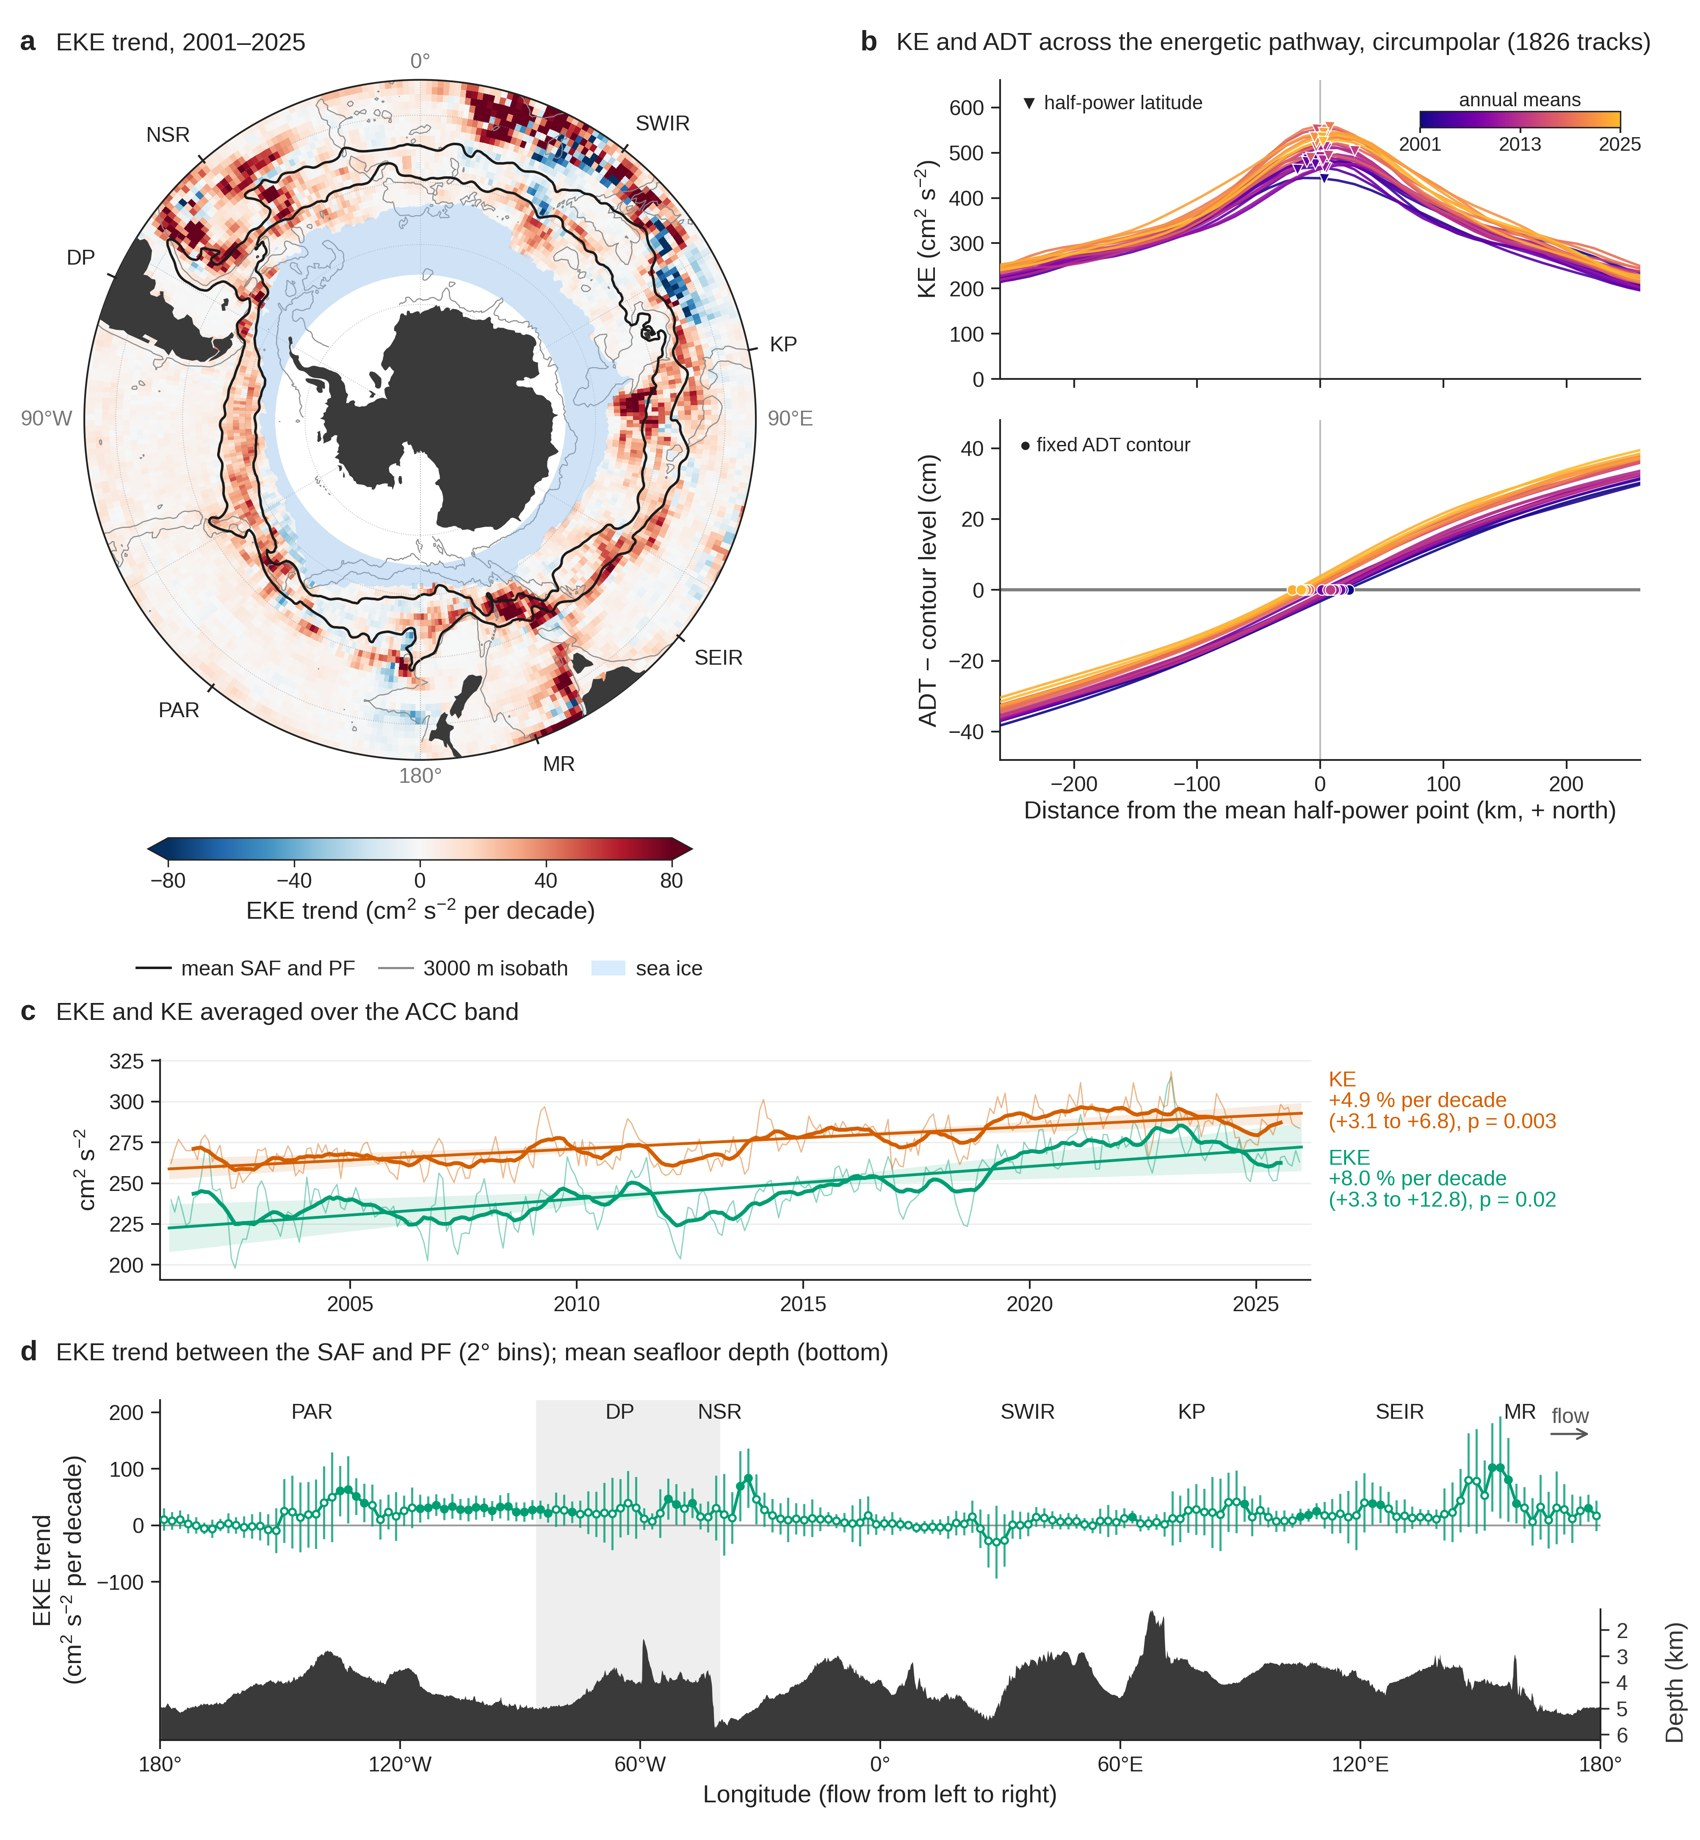

Figure3.png written to /tmp/osr11_nb_4ttckl0d/png


In [5]:
render("fig3_circumpolar.py")

## All-satellite against two-satellite product (Fig. S3)

The diagnostics above repeated with the two-satellite climate product (Product 4), with the same methods (`scripts/06_product4/`). `p4_summary.csv` holds every pair of values.

In [6]:
P4 = pd.read_csv(OUT / "p4" / "p4_summary.csv")
show = ["ACC band EKE trend 2001-2025", "ACC band KE trend 2001-2025", "ACC band EKE: 2018-2025 mean over 2001-2017 mean",
        "Half-power latitude trend, circumpolar, RELATIVE threshold (20 % of local max; main text)",
        "2-deg bins: correlation of P1 and P4 EKE trends", "EKE: maximum lagged correlation with wind stress (wind leading 0-36 months)", "EKE: lag of the maximum correlation"]
P4[P4.quantity.isin(show)].drop_duplicates("quantity")[["quantity", "unit", "P1", "P1_lo", "P1_hi", "P1_p", "P4", "P4_lo", "P4_hi", "P4_p"]].round(3)

,quantity,unit,P1,P1_lo,P1_hi,P1_p,P4,P4_lo,P4_hi,P4_p
0,ACC band KE trend 2001-2025,% of mean per decade,4.94,3.12,6.76,0.003,3.63,2.09,5.17,0.003
3,ACC band EKE trend 2001-2025,% of mean per decade,8.02,3.28,12.8,0.017,3.79,1.33,6.26,0.02
29,"Half-power latitude trend, circumpolar, RELATI...",km per decade (north +),2.59,-5.95,11.1,0.458,NaN,NaN,NaN,NaN
36,2-deg bins: correlation of P1 and P4 EKE trends,Pearson r,0.898,NaN,NaN,NaN,NaN,NaN,NaN,NaN
65,ACC band EKE: 2018-2025 mean over 2001-2017 mean,%,13.1,NaN,NaN,NaN,5.78,NaN,NaN,NaN
74,EKE: maximum lagged correlation with wind stre...,r,0.474,NaN,NaN,0.113,0.506,NaN,NaN,0.007
75,EKE: lag of the maximum correlation,months (95 % block-bootstrap range in lo/hi),11,8,23,NaN,9,5,21,NaN


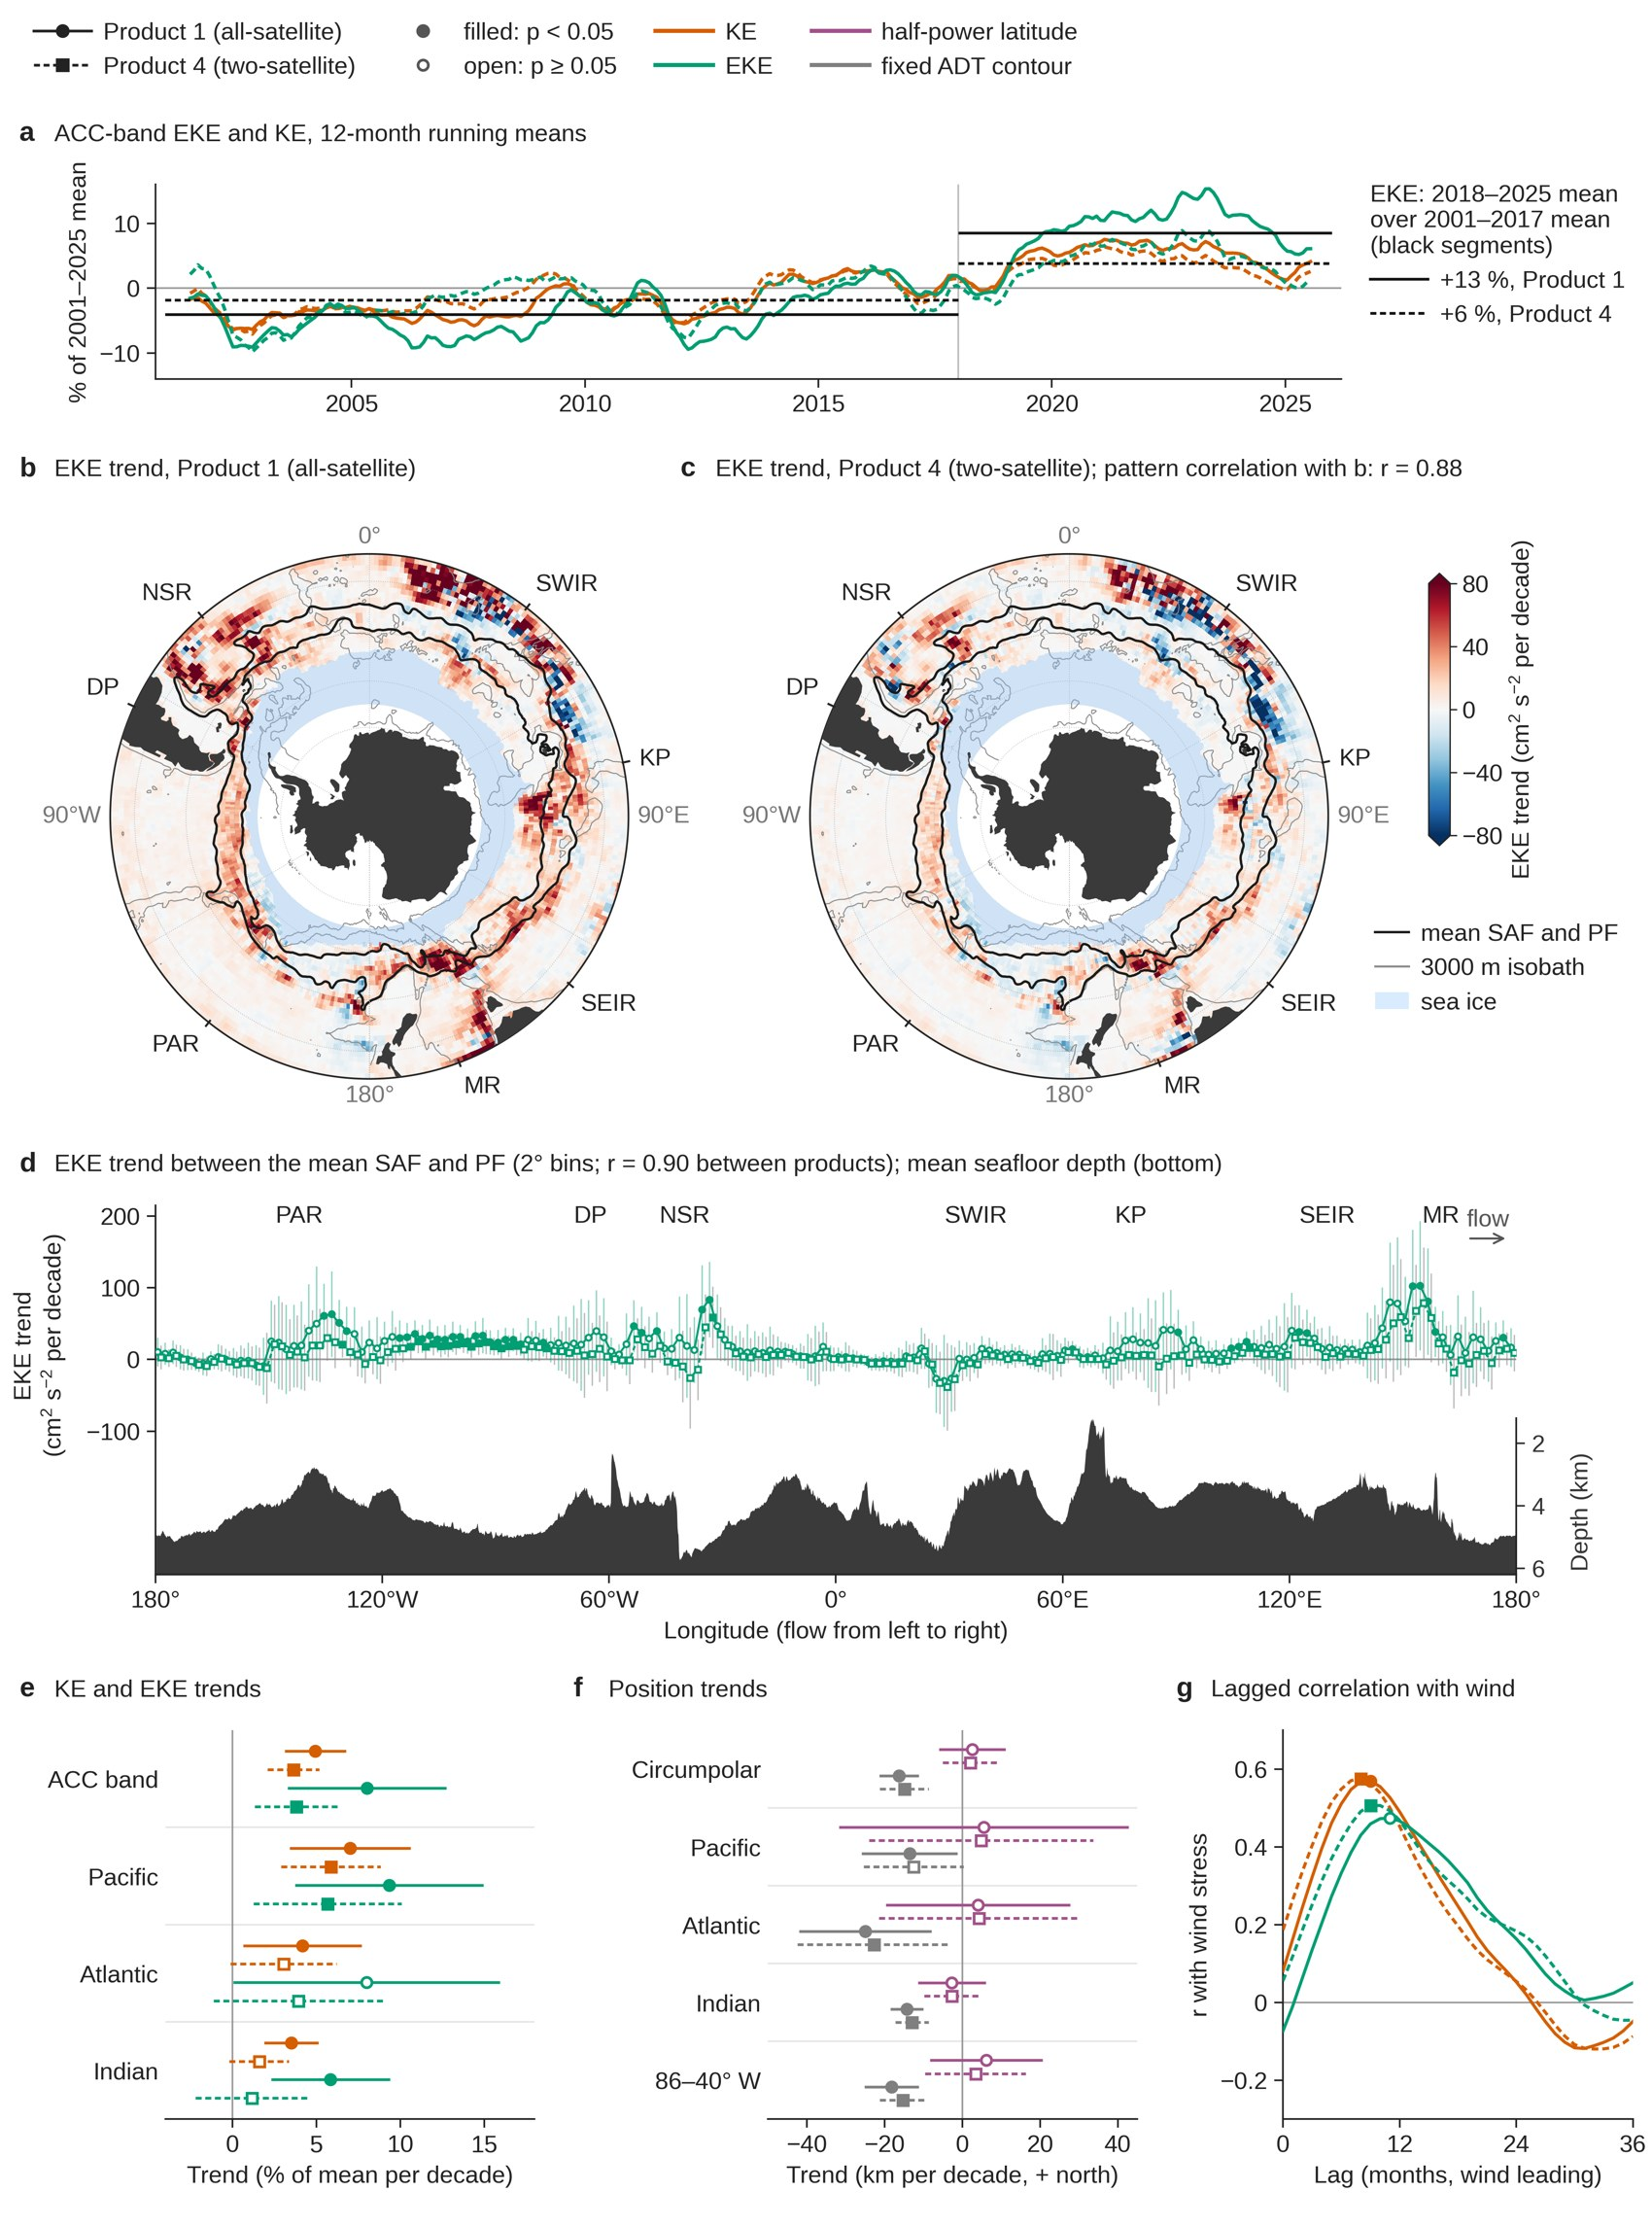

FigureS3.png written to /tmp/osr11_nb_4ttckl0d/png


In [7]:
render("figS3_products.py")

## Comparison with previous studies (Fig. S4)

Our trends recomputed for the regions and periods of earlier studies (`scripts/05_stats/05k_previous_studies.py`), and the lag of EKE behind the SAM index computed as in Hogg et al. (2015) (`05l_sam_lag.py`).

In [8]:
L = pd.read_csv(OUT / "x11" / "x11_summary.csv"); L

,variant,region,lag_max_months,r_max,p_pt_max,p_fw_max,r_lag0yr,r_lag1yr,r_lag2yr,r_lag3yr,r_lag4yr,p_pt_lag0yr,p_pt_lag1yr,p_pt_lag2yr,p_pt_lag3yr,p_pt_lag4yr
0,as Hogg et al. (2015): not detrended,Pacific,10,0.429,0.008,0.0575,0.296,0.425,0.274,0.146,0.0214,0.139,0.0105,0.176,0.528,0.932
1,as Hogg et al. (2015): not detrended,Indian,6,0.455,0.018,0.122,0.362,0.395,0.242,0.0323,-0.063,0.108,0.0575,0.294,0.898,0.795
2,as Hogg et al. (2015): not detrended,Atlantic,7,0.3,0.188,0.712,0.261,0.278,0.0787,-0.18,0.151,0.274,0.212,0.701,0.433,0.512
3,as Hogg et al. (2015): not detrended,ACC band,3,0.374,0.0615,0.243,0.353,0.311,0.151,0.0185,0.00695,0.088,0.143,0.557,0.942,0.982
4,both detrended,Pacific,9,0.165,0.258,0.834,0.0108,0.148,0.0975,0.104,0.0254,0.934,0.308,0.501,0.473,0.86
5,both detrended,Indian,5,0.239,0.312,0.923,0.109,0.0824,0.034,-0.085,-0.113,0.68,0.743,0.891,0.73,0.643
6,both detrended,Atlantic,48,0.184,0.472,0.992,0.0421,0.0156,-0.119,-0.309,0.184,0.876,0.946,0.649,0.192,0.472
7,both detrended,ACC band,2,0.0929,0.667,1,0.0757,-0.106,-0.155,-0.126,0.00255,0.737,0.615,0.469,0.589,0.995


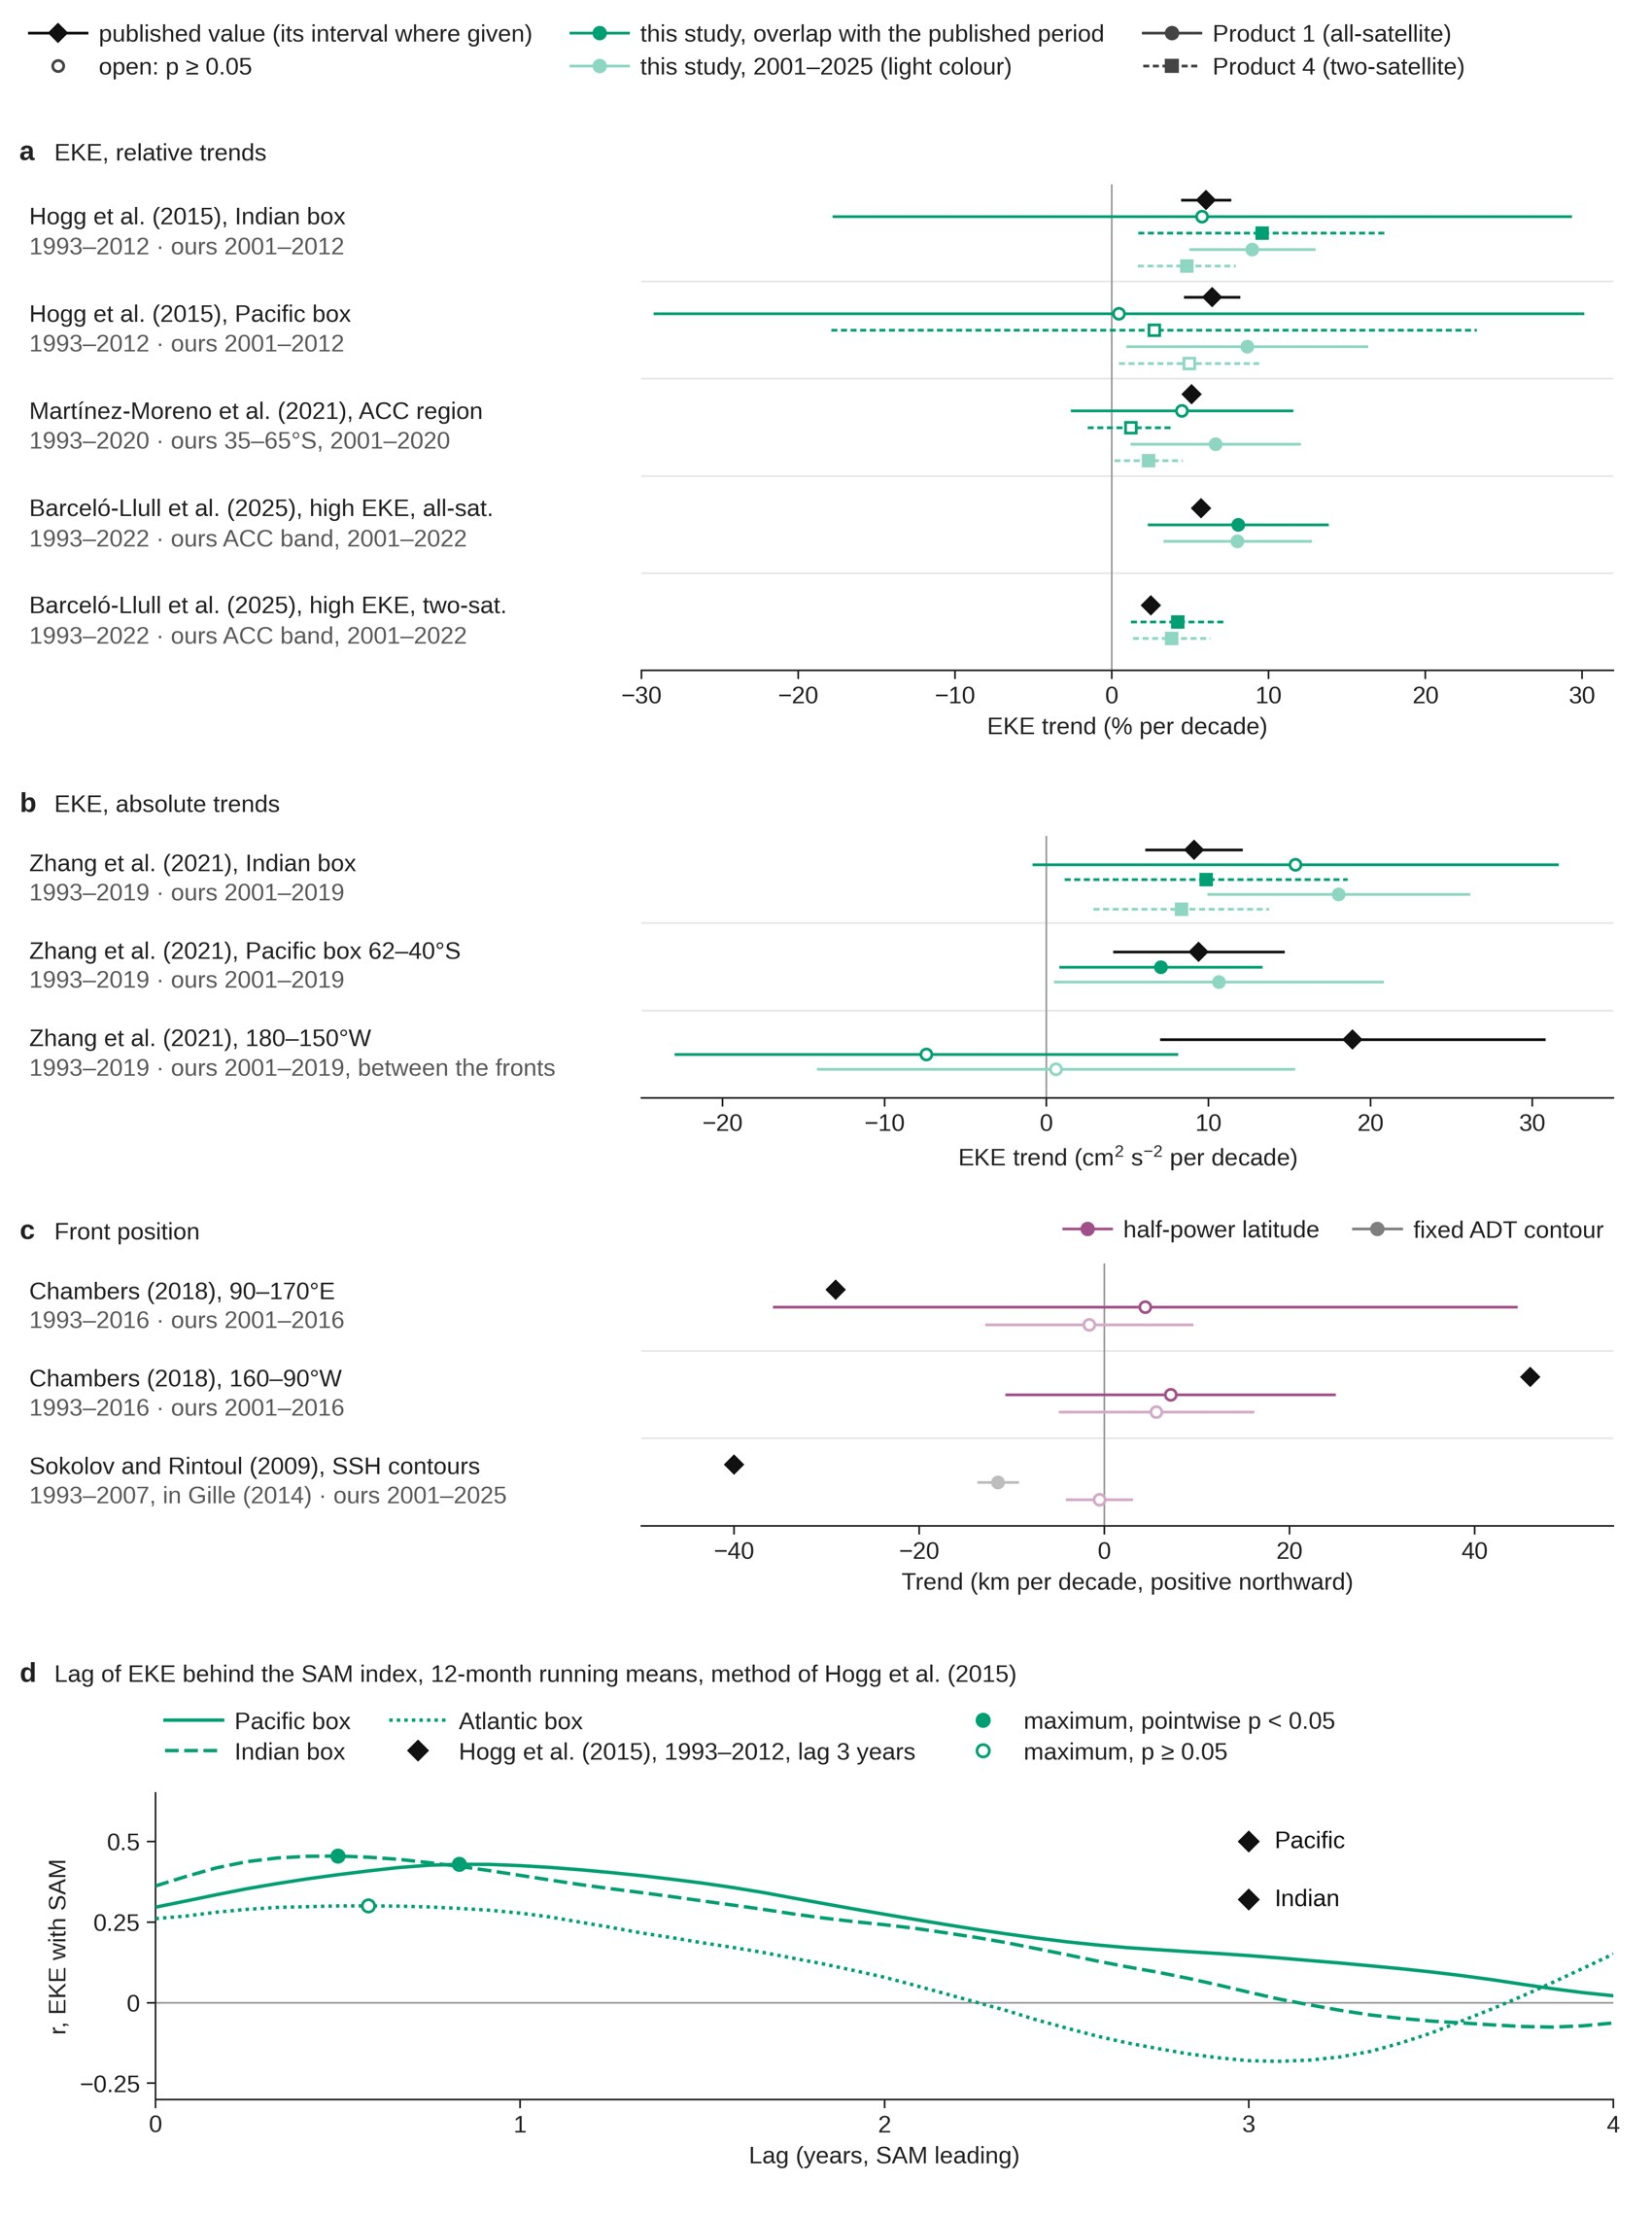

FigureS4.png written to /tmp/osr11_nb_4ttckl0d/png


In [9]:
render("figS4_previous_studies.py")

## Occurrence of the half-power points and height of the pathway (Fig. S6)

In [10]:
import json
ov = json.load(open(OUT / "s6" / "s6_occurrence_relthr.json"))["relative_threshold"]
print(json.dumps(ov, indent=1)[:900])

{
 "drake": {
  "split2018": 0.6479,
  "split2016": 0.6765,
  "split2018_level5": 0.8444,
  "split2018_level15": 0.6318,
  "split2018_without_malvinas_exclusion": 0.6479,
  "null_17_8_median": 0.6144,
  "null_q05_q95": [
   0.5482,
   0.6792
  ],
  "P_null_le_obs": 0.7915,
  "n_points_in_grid": 149179,
  "x3_json_obs18": 0.6479,
  "x3_json_null_med": 0.6144
 },
 "circ": {
  "split2018": 0.8281,
  "split2016": 0.8318,
  "split2018_level5": 0.9215,
  "split2018_level15": 0.6577,
  "split2018_without_malvinas_exclusion": 0.8295,
  "null_17_8_median": 0.8504,
  "null_q05_q95": [
   0.8352,
   0.8642
  ],
  "P_null_le_obs": 0.0075,
  "n_points_in_grid": 1152121,
  "x3_json_obs18": 0.8295,
  "x3_json_null_med": 0.8502
 }
}


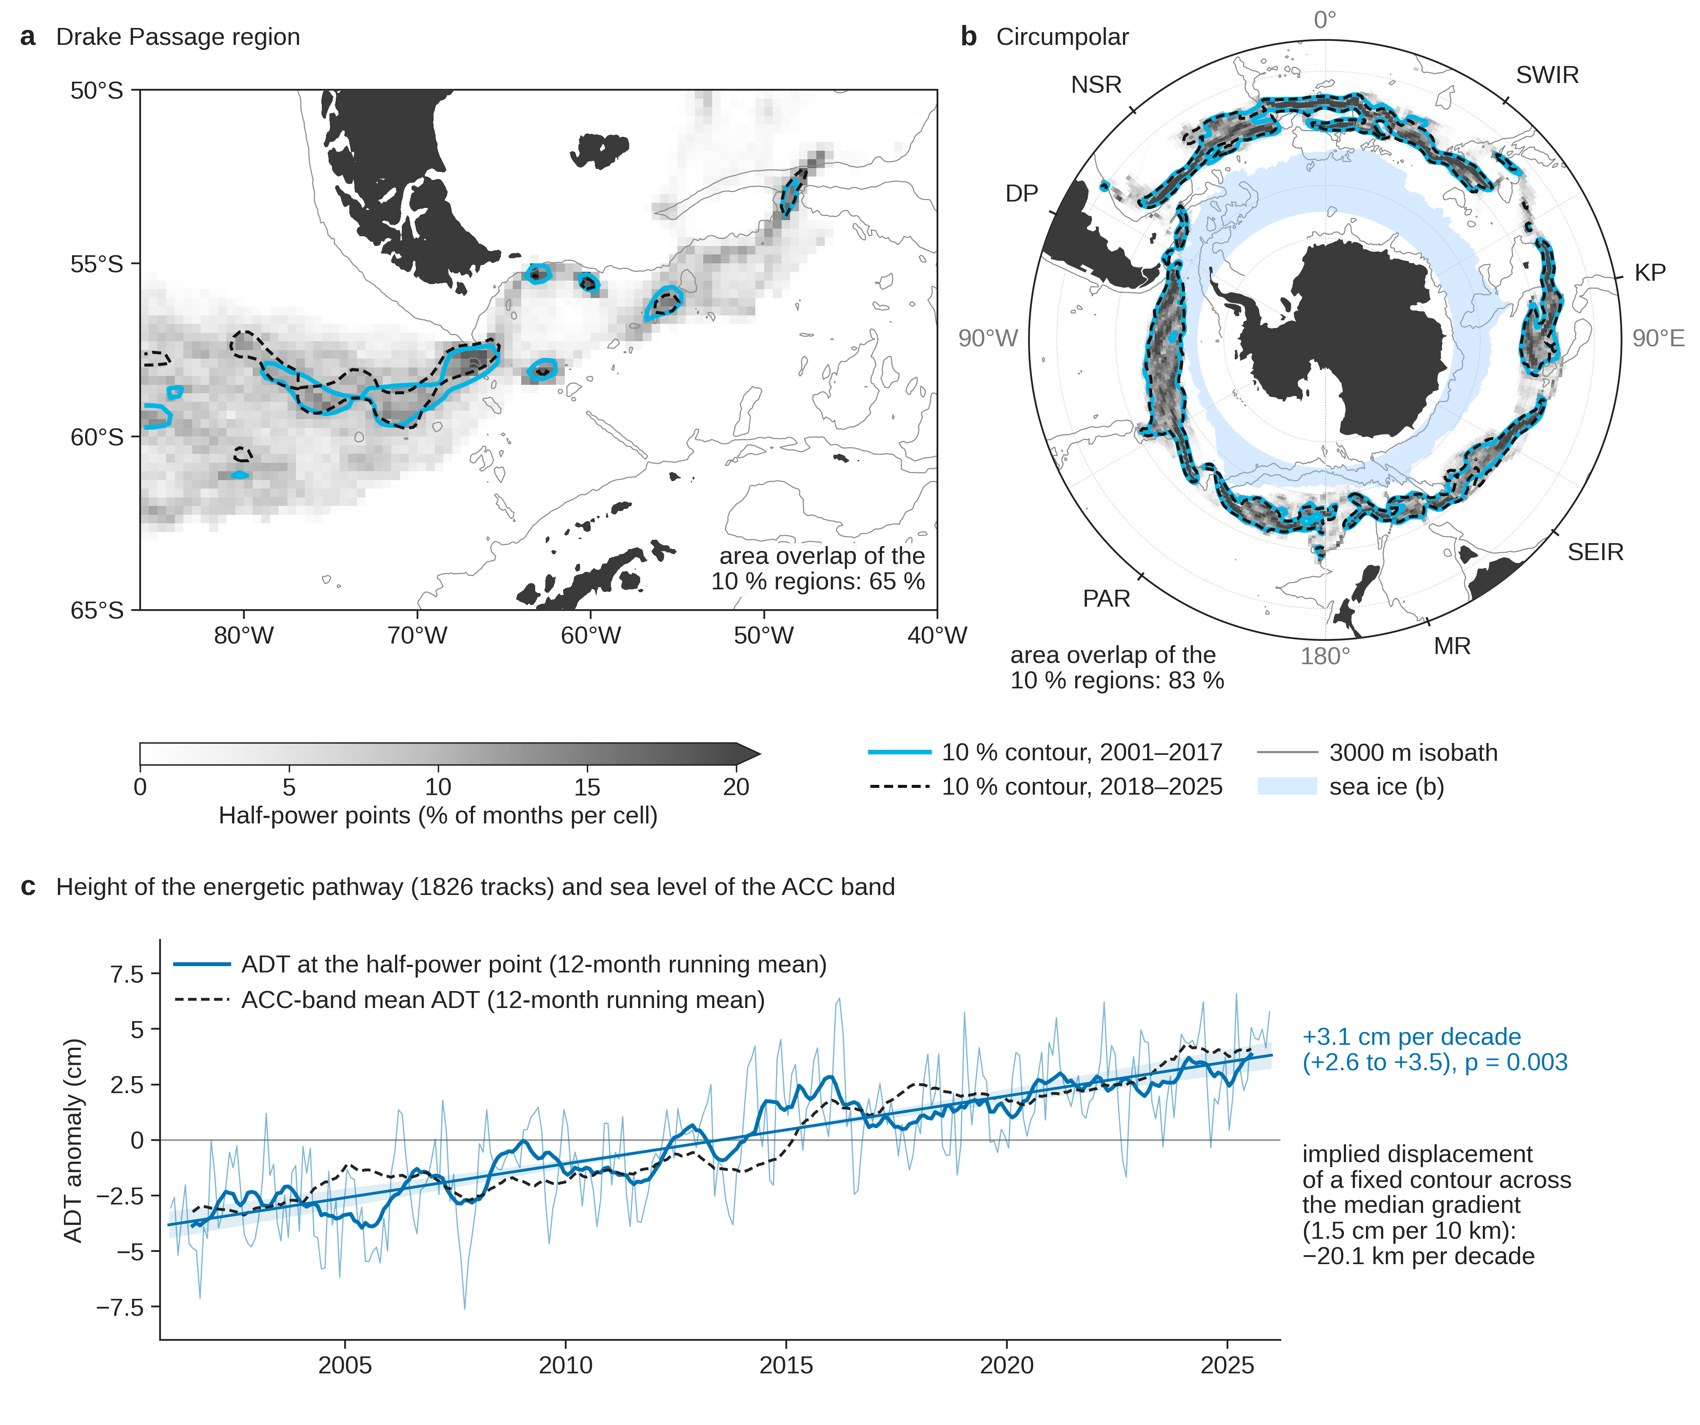

FigureS6.png written to /tmp/osr11_nb_4ttckl0d/png


In [11]:
render("figS6_occurrence_adt.py")

## Position by longitude (Fig. S7)

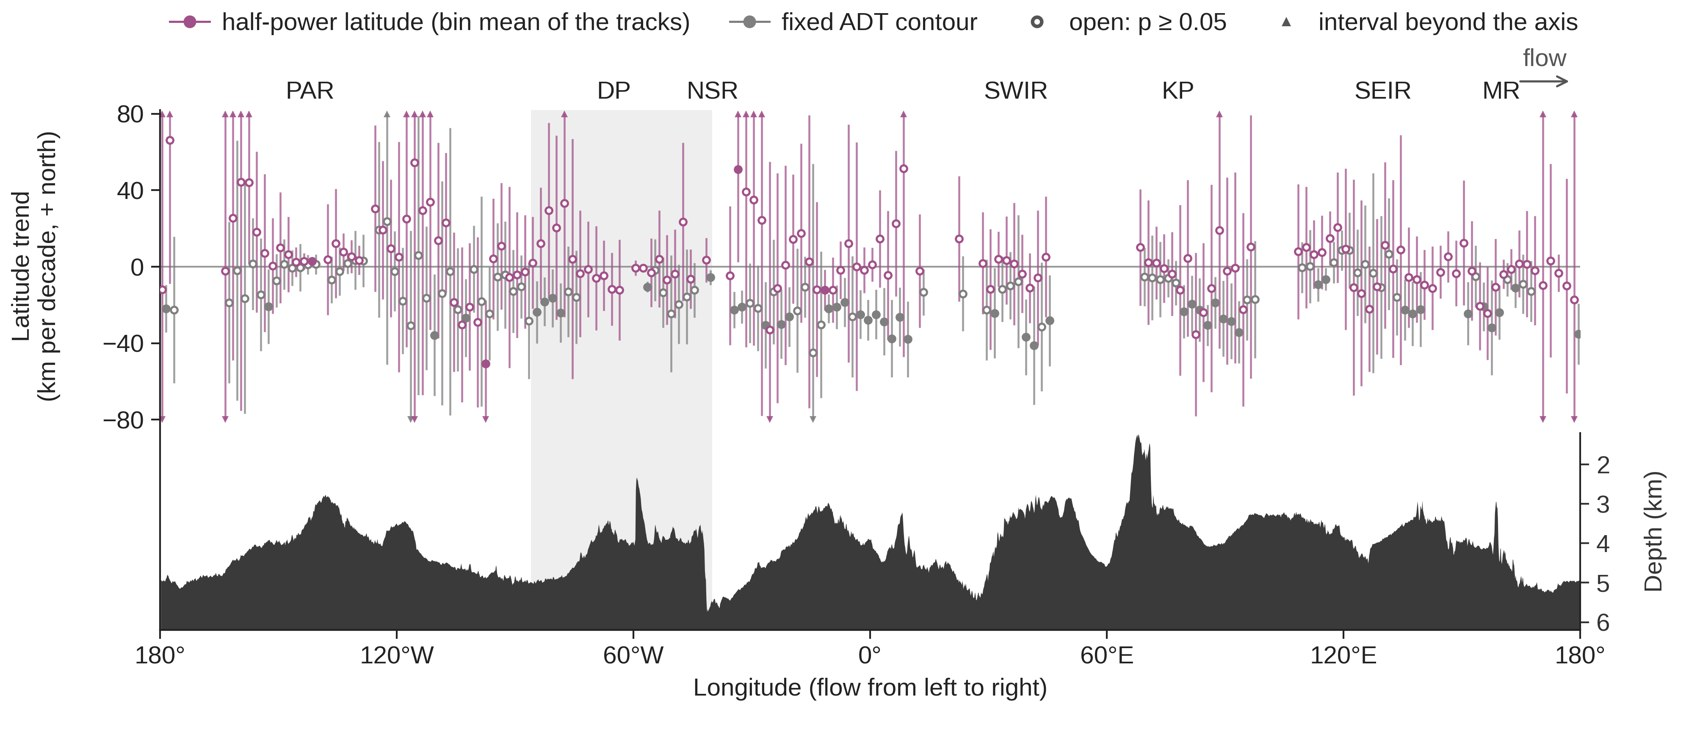

FigureS7.png written to /tmp/osr11_nb_4ttckl0d/png


In [12]:
render("figS7_position_longitude.py")